# Impact of Missing Clinical Data and Median Imputation on a Diabetes Prediction Model

## Project Overview

This project explores how missing clinical data and median imputation affect the performance of a diabetes prediction model using a synthetic dataset of 583 adult records.

A logistic regression model is first trained and evaluated using the complete dataset. Approximately 10% missing values are then introduced randomly into five clinical variables: BMI, glucose, HbA1c, systolic blood pressure, and diastolic blood pressure. Median imputation is applied before training and evaluating the model under the missing-data condition.

The purpose of this project is not to develop a clinical diagnostic tool, but to demonstrate how data quality and preprocessing decisions can influence model performance in a controlled synthetic-data experiment.

## Research Question

**How does introducing approximately 10% random missingness in selected clinical variables and applying median imputation affect the performance of a logistic regression model for diabetes prediction?**

## 1. Data Loading and Initial Inspection

The synthetic dataset is loaded and inspected to examine its dimensions, variables, data types, and diabetes outcome distribution before analysis.

In [1]:
import pandas as pd

df = pd.read_csv("/content/diabetes_data_quality_synthetic_583.csv")

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset loaded successfully!
Rows: 583
Columns: 15


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     583 non-null    int64  
 1   sex                     583 non-null    int64  
 2   BMI                     583 non-null    float64
 3   hypertension            583 non-null    int64  
 4   heart_disease           583 non-null    int64  
 5   smoking                 583 non-null    int64  
 6   physical_activity_days  583 non-null    int64  
 7   glucose_mg_dL           583 non-null    float64
 8   HbA1c_percent           583 non-null    float64
 9   systolic_BP             583 non-null    float64
 10  diastolic_BP            583 non-null    float64
 11  HDL_mg_dL               583 non-null    float64
 12  LDL_mg_dL               583 non-null    float64
 13  triglycerides_mg_dL     583 non-null    float64
 14  diabetes                583 non-null    in

In [3]:
df.head(10)

,age,sex,BMI,hypertension,heart_disease,smoking,physical_activity_days,glucose_mg_dL,HbA1c_percent,systolic_BP,diastolic_BP,HDL_mg_dL,LDL_mg_dL,triglycerides_mg_dL,diabetes
0,52,1,24.6,0,0,0,3,78.0,5.3,118.0,73.0,56.1,120.5,69.0,0
1,34,0,31.1,0,0,0,6,81.4,5.0,125.0,79.0,63.3,114.3,115.0,0
2,58,1,28.1,0,0,1,7,75.7,5.0,126.0,73.0,59.9,125.0,172.0,0
3,60,0,27.5,1,0,1,3,96.7,6.8,144.0,74.0,62.7,104.9,108.0,1
4,23,1,35.2,0,0,1,3,119.9,5.1,105.0,72.0,48.0,103.7,205.0,0
5,31,1,16.0,0,0,0,0,60.0,4.4,94.0,74.0,51.5,91.7,61.0,0
6,50,1,20.1,1,0,1,7,63.2,4.6,136.0,72.0,45.3,64.6,114.0,0
7,44,1,21.3,0,0,0,0,60.0,4.8,127.0,64.0,49.4,111.8,111.0,0
8,48,0,25.6,1,0,1,0,90.1,5.1,121.0,80.0,58.0,82.7,107.0,0
9,37,1,26.2,1,0,0,3,60.0,5.1,135.0,81.0,45.7,130.1,109.0,0


In [4]:
df["diabetes"].value_counts()

,count
diabetes,
0,502
1,81


## 2. Exploratory Data Analysis

The dataset is explored to examine the distribution of diabetes status and differences in selected clinical characteristics between the diabetes and non-diabetes groups. Group means are summarized for age, BMI, glucose, and HbA1c, followed by statistical comparisons of glucose and HbA1c.

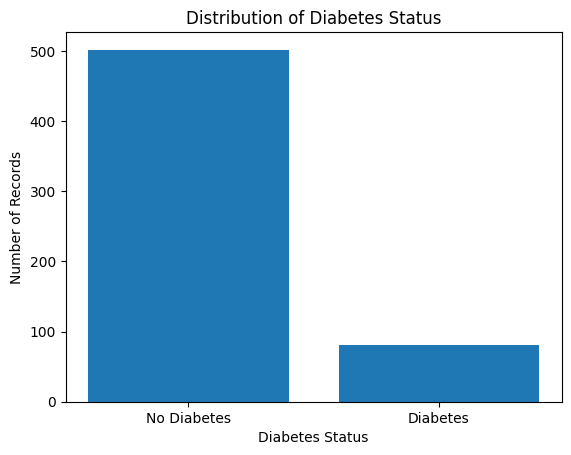

In [21]:
import matplotlib.pyplot as plt

counts = df["diabetes"].value_counts().sort_index()

plt.bar(["No Diabetes", "Diabetes"], counts.values)
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Records")
plt.title("Distribution of Diabetes Status")

plt.savefig("diabetes_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
df.groupby("diabetes")[["age", "BMI", "glucose_mg_dL", "HbA1c_percent"]].mean()

,age,BMI,glucose_mg_dL,HbA1c_percent
diabetes,,,,
0,46.043825,26.515139,87.713944,5.174701
1,58.074074,30.917284,114.834568,5.908642


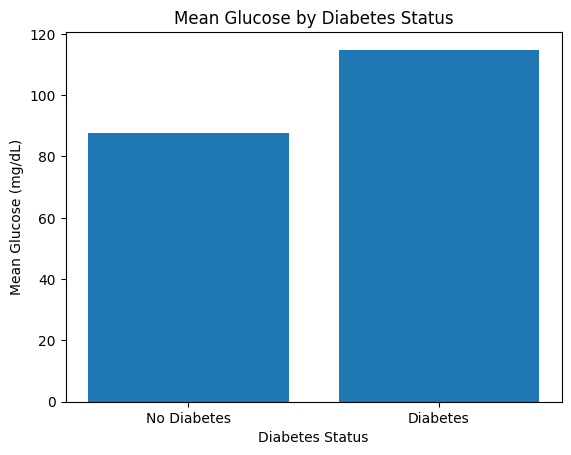

In [7]:
import matplotlib.pyplot as plt

mean_glucose = df.groupby("diabetes")["glucose_mg_dL"].mean()

plt.bar(["No Diabetes", "Diabetes"], mean_glucose.values)
plt.xlabel("Diabetes Status")
plt.ylabel("Mean Glucose (mg/dL)")
plt.title("Mean Glucose by Diabetes Status")
plt.show()

In [8]:
from scipy.stats import ttest_ind

no_diabetes = df[df["diabetes"] == 0]["glucose_mg_dL"]
diabetes = df[df["diabetes"] == 1]["glucose_mg_dL"]

t_stat, p_value = ttest_ind(
    no_diabetes,
    diabetes,
    equal_var=False
)

print("t-statistic:", t_stat)
print("p-value:", p_value)

t-statistic: -10.303267648271737
p-value: 1.5443744154239037e-17


In [9]:
from scipy.stats import ttest_ind

no_diabetes_hba1c = df[df["diabetes"] == 0]["HbA1c_percent"]
diabetes_hba1c = df[df["diabetes"] == 1]["HbA1c_percent"]

t_stat, p_value = ttest_ind(
    no_diabetes_hba1c,
    diabetes_hba1c,
    equal_var=False
)

print("t-statistic:", t_stat)
print("p-value:", p_value)


t-statistic: -11.755310391677295
p-value: 6.4913315770795294e-21


## 3. Clean-Data Logistic Regression Model

The dataset is divided into training and test sets using an 80/20 stratified split to preserve the proportion of diabetes cases. A logistic regression model is trained on the complete data, with feature standardization applied before model fitting.

Model performance is evaluated using accuracy, sensitivity, specificity, positive predictive value (PPV), negative predictive value (NPV), and ROC-AUC.

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop("diabetes", axis=1)
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 466
Testing records: 117


In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [12]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 117


In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nConfusion Matrix:")
print(cm)

Accuracy: 0.905982905982906

Confusion Matrix:
[[97  4]
 [ 7  9]]


In [14]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score
)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
ppv = precision_score(y_test, y_pred)
npv = tn / (tn + fn)

print(f"Accuracy: {accuracy:.2%}")
print(f"Sensitivity: {sensitivity:.2%}")
print(f"Specificity: {specificity:.2%}")
print(f"PPV: {ppv:.2%}")
print(f"NPV: {npv:.2%}")

Accuracy: 90.60%
Sensitivity: 56.25%
Specificity: 96.04%
PPV: 69.23%
NPV: 93.27%


In [15]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", round(auc, 3))

ROC-AUC: 0.893


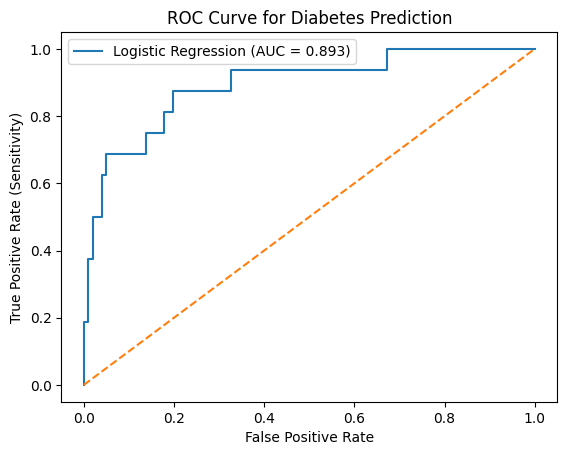

In [16]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve for Diabetes Prediction")
plt.legend()

plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Missing-Data Experiment

To simulate a data-quality problem, approximately 10% of values are randomly set to missing in five clinical variables: BMI, glucose, HbA1c, systolic blood pressure, and diastolic blood pressure. Missingness is introduced separately into the training and test sets using a fixed random seed for reproducibility.

Median imputation is then applied within the modelling pipeline, followed by feature standardization and logistic regression. The imputer is fitted only on the training data to avoid data leakage.


In [17]:
import numpy as np

# Create copies of the original train and test predictor sets
X_train_missing = X_train.copy()
X_test_missing = X_test.copy()

# Set seed for reproducibility
np.random.seed(42)

columns_to_damage = [
    "BMI",
    "glucose_mg_dL",
    "HbA1c_percent",
    "systolic_BP",
    "diastolic_BP"
]

# Introduce 10% missing values separately into training and test data
for column in columns_to_damage:
    train_missing_indices = np.random.choice(
        X_train_missing.index,
        size=int(0.10 * len(X_train_missing)),
        replace=False
    )

    test_missing_indices = np.random.choice(
        X_test_missing.index,
        size=int(0.10 * len(X_test_missing)),
        replace=False
    )

    X_train_missing.loc[train_missing_indices, column] = np.nan
    X_test_missing.loc[test_missing_indices, column] = np.nan

print("Missing values introduced successfully!")

print("\nTraining data:")
print(X_train_missing[columns_to_damage].isnull().sum())

print("\nTest data:")
print(X_test_missing[columns_to_damage].isnull().sum())

Missing values introduced successfully!

Training data:
BMI              46
glucose_mg_dL    46
HbA1c_percent    46
systolic_BP      46
diastolic_BP     46
dtype: int64

Test data:
BMI              11
glucose_mg_dL    11
HbA1c_percent    11
systolic_BP      11
diastolic_BP     11
dtype: int64


In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the missing-data model pipeline
# Median imputation is learned from the training data only
model_missing = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train on the damaged training data
model_missing.fit(X_train_missing, y_train)

print("Missing-data model trained successfully!")

Missing-data model trained successfully!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    recall_score,
    precision_score,
    roc_auc_score
)

# Predictions from the missing-data model
y_pred_missing = model_missing.predict(X_test_missing)

# Probability predictions for ROC-AUC
y_prob_missing = model_missing.predict_proba(X_test_missing)[:, 1]

# Confusion matrix
cm_missing = confusion_matrix(y_test, y_pred_missing)

print("Confusion Matrix:")
print(cm_missing)

# Extract confusion matrix values
tn_m, fp_m, fn_m, tp_m = cm_missing.ravel()

# Calculate performance metrics
accuracy_missing = accuracy_score(y_test, y_pred_missing)
sensitivity_missing = recall_score(y_test, y_pred_missing)
specificity_missing = tn_m / (tn_m + fp_m)
ppv_missing = precision_score(y_test, y_pred_missing)
npv_missing = tn_m / (tn_m + fn_m)
roc_auc_missing = roc_auc_score(y_test, y_prob_missing)

print("\nMissing Data + Median Imputation Model Metrics:")
print(f"Accuracy: {accuracy_missing:.2%}")
print(f"Sensitivity: {sensitivity_missing:.2%}")
print(f"Specificity: {specificity_missing:.2%}")
print(f"PPV: {ppv_missing:.2%}")
print(f"NPV: {npv_missing:.2%}")
print(f"ROC-AUC: {roc_auc_missing:.3f}")

Confusion Matrix:
[[97  4]
 [ 6 10]]

Missing Data + Median Imputation Model Metrics:
Accuracy: 91.45%
Sensitivity: 62.50%
Specificity: 96.04%
PPV: 71.43%
NPV: 94.17%
ROC-AUC: 0.881


## 5. Model Performance Comparison

Performance of the clean-data model is compared with the model trained and evaluated after introducing approximately 10% random missingness and applying median imputation. The comparison includes accuracy, sensitivity, specificity, PPV, NPV, and ROC-AUC.

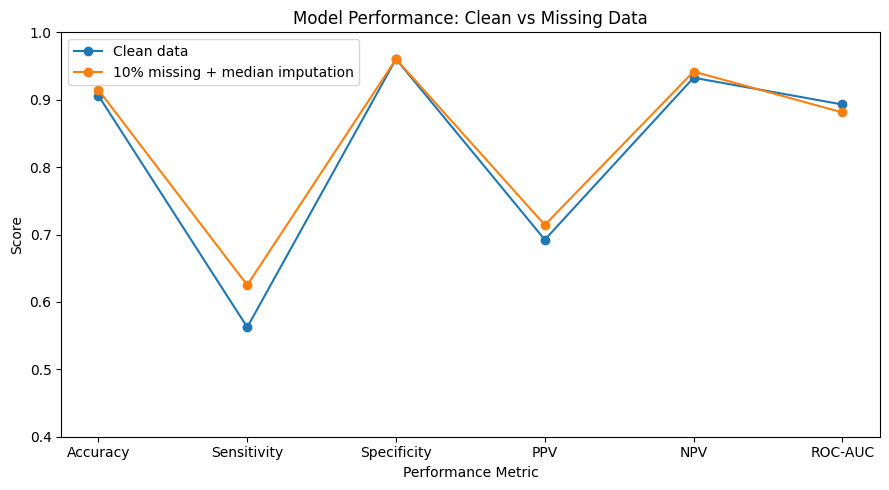

In [20]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Sensitivity", "Specificity", "PPV", "NPV", "ROC-AUC"]

# Use the results calculated earlier instead of hard-coded values
clean_scores = [
    accuracy,
    sensitivity,
    specificity,
    ppv,
    npv,
    auc
]

missing_scores = [
    accuracy_missing,
    sensitivity_missing,
    specificity_missing,
    ppv_missing,
    npv_missing,
    roc_auc_missing
]

x = range(len(metrics))

plt.figure(figsize=(9, 5))

plt.plot(x, clean_scores, marker="o", label="Clean data")
plt.plot(x, missing_scores, marker="o", label="10% missing + median imputation")

plt.xticks(x, metrics)
plt.ylim(0.4, 1.0)

plt.xlabel("Performance Metric")
plt.ylabel("Score")
plt.title("Model Performance: Clean vs Missing Data")
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Results and Interpretation

The clean-data model achieved 90.60% accuracy, 56.25% sensitivity, 96.04% specificity, 69.23% PPV, 93.27% NPV, and a ROC-AUC of 0.893.

After introducing approximately 10% random missingness and applying median imputation, accuracy was 91.45%, sensitivity was 62.50%, specificity was 96.04%, PPV was 71.43%, NPV was 94.17%, and ROC-AUC was 0.881.

In this simulation, missingness followed by median imputation did not uniformly reduce model performance. Several threshold-based metrics showed small increases, while ROC-AUC decreased from 0.893 to 0.881, indicating slightly lower overall discrimination. These differences should be interpreted cautiously because the experiment used a single train-test split and one random missingness simulation.

## 7. Limitations

This project uses synthetic data and therefore does not represent real-world clinical populations. The analysis is based on a single train-test split and one random missingness simulation, so the observed differences in model performance may vary with a different split or random seed.

Missing values were introduced randomly in selected variables, which represents only one type of missing-data scenario. Only median imputation and logistic regression were evaluated. The relatively small number of diabetes cases in the test set also makes sensitivity particularly responsive to changes in a small number of predictions.

The model has not been externally or clinically validated and should not be used for medical diagnosis or decision-making.